# Extracted ion chromatograms

Estimate the area of a chromatographic peak with a known generating curve.

An extracted ion chromatogram sums intensities in a narrow mass window at each acquisition time. Subtracting a known baseline and integrating over retention time gives an area with intensity-time units.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from peptide_methods import gaussian
from scipy.integrate import trapezoid

## Work through the data

The calculation prints its numerical result and plots the observations that produced it.

area 645.206, analytic 645.206, relative error 1.76e-16


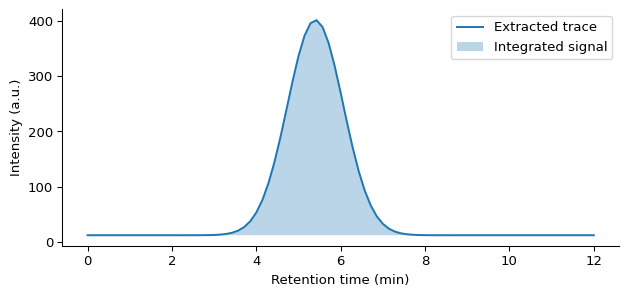

In [2]:
t = np.linspace(0, 12, 85)
centre = 5.4
width = 0.66
amplitude = 390
baseline = 12.0
target = 511.2
masses = np.array([511.197, 511.201, 511.263])
signal = amplitude * gaussian(t, centre, width)
spectra = np.stack([0.3 * signal + 4, 0.7 * signal + 8, 250 * gaussian(t, 6.7, 0.8)], axis=1)
trace = spectra[:, abs(masses - target) <= 0.006].sum(1)
area = trapezoid(trace - baseline, t)
expected = amplitude * width * np.sqrt(2 * np.pi)
print(
    f"area {area:.3f}, analytic {expected:.3f}, relative error {abs(area-expected)/expected:.2e}"
)
assert np.isclose(area, expected, rtol=1e-6)
fig, ax = plt.subplots(figsize=(6.5, 3), constrained_layout=True)
ax.plot(t, trace, label="Extracted trace")
ax.fill_between(t, baseline, trace, alpha=0.3, label="Integrated signal")
ax.set(xlabel="Retention time (min)", ylabel="Intensity (a.u.)")
ax.legend()
plt.show()

## Interpreting the result

A wider mass window admits the interfering peak at 511.263 and changes the answer even with a perfectly known baseline.

## Exercise

Repeat at three extraction tolerances and compare the areas.

## References

[SciPy, trapezoidal integration](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.trapezoid.html)